In [ ]:
import io
import requests
import numpy as np

print("Downloading dataset...")
url = 'https://osf.io/sy5xt/download'
response = requests.get(url)

if response.status_code != 200:
    print('Failed to download data. Check your connection.')
else:
    print("Download complete. Loading data...")
    # Read the downloaded data into a NumPy array
    spike_times = np.load(io.BytesIO(response.content), allow_pickle=True)['spike_times']

    print(f"Success! Loaded spike times for {len(spike_times)} neurons.")

Download complete. Loading data...
Success! Loaded spike times for 734 neurons.


In [ ]:
import io
import requests
import numpy as np

print("Downloading the comprehensive Steinmetz dataset...")
url = 'https://osf.io/agvxh/download'
response = requests.get(url)

# 1. Load the full dataset which includes brain area metadata
data = np.load(io.BytesIO(response.content), allow_pickle=True)

# The dataset groups recordings by session. We extract the first session (index 0).
alldat = data['dat'][0]

# 2. Identify the Visual Cortex Neurons
brain_areas = alldat['brain_area']
# 'VISp' stands for Primary Visual Cortex. np.where finds the row indices for these neurons.
visp_indices = np.where(brain_areas == 'VISp')[0]
print(f"Found {len(visp_indices)} neurons in the primary visual cortex (VISp).")

# 3. Extract the Neural Activity
# 'spks' is a 3D matrix structured as: (neurons, trials, time_bins)
spks = alldat['spks']
visp_spks = spks[visp_indices]

# 4. Calculate the Average Firing Rate
# Total recording time in seconds = (number of trials) * (number of time bins) * (10ms per bin)
num_trials = visp_spks.shape[1]
num_time_bins = visp_spks.shape[2]
total_time_seconds = num_trials * num_time_bins * 0.01

# np.sum adds up all the spikes across axis 1 (trials) and axis 2 (time bins) for each neuron
total_spikes_per_neuron = np.sum(visp_spks, axis=(1, 2))

# Firing Rate (Hz) is total spikes divided by total time in seconds
average_firing_rates = total_spikes_per_neuron / total_time_seconds

grand_avg_rate = np.mean(average_firing_rates)
print(f"Grand average firing rate for VISp neurons: {grand_avg_rate:.2f} Hz")

Found 178 neurons in the primary visual cortex (VISp).
Grand average firing rate for VISp neurons: 3.78 Hz


Original data shape: (178, 250) (Neurons, Time Bins)
PCA reduced shape: (178, 2) (Neurons, Principal Components)


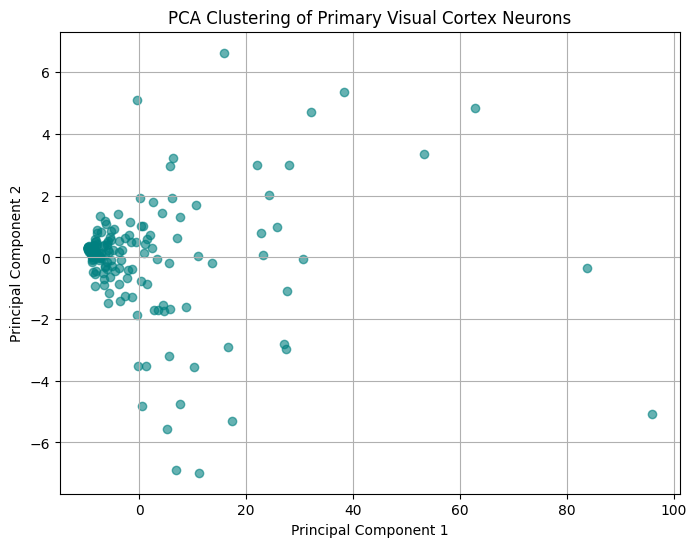

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Extract the firing pattern over time
# Average across axis 1 (trials) to get a matrix of (neurons, time_bins)
time_varying_rates = np.mean(visp_spks, axis=1)

# 2. Standardize the data
# PCA is highly sensitive to the scale of the data. We standardize it so
# neurons with high overall firing rates don't dominate the clustering.
scaler = StandardScaler()
scaled_rates = scaler.fit_transform(time_varying_rates)

# 3. Perform PCA
# Initialize the PCA model to reduce the data to 2 components
pca = PCA(n_components=2)
# Fit the model to our data and transform it in one step
pca_result = pca.fit_transform(scaled_rates)

print(f"Original data shape: {scaled_rates.shape} (Neurons, Time Bins)")
print(f"PCA reduced shape: {pca_result.shape} (Neurons, Principal Components)")

# 4. Visualize the results
plt.figure(figsize=(8, 6))
# Plot Component 1 on the X-axis and Component 2 on the Y-axis
plt.scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.6, color='teal')
plt.title('PCA Clustering of Primary Visual Cortex Neurons')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

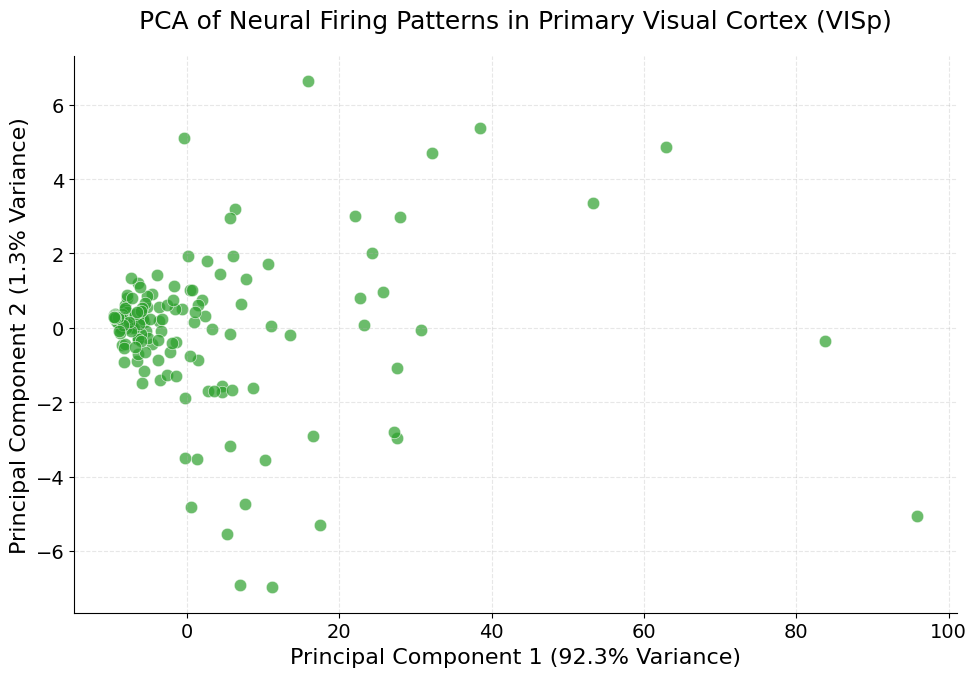

In [ ]:
import matplotlib.pyplot as plt

# 1. Configure global aesthetic settings for a professional presentation
plt.rcParams.update({
    'font.size': 14,             # Larger baseline text for presentations
    'axes.labelsize': 16,        # Larger X/Y axis labels
    'axes.titlesize': 18,        # Larger title
    'axes.spines.top': False,    # Remove top border (scientific standard)
    'axes.spines.right': False,  # Remove right border
    'figure.figsize': (10, 7)    # Widescreen-friendly aspect ratio
})

fig, ax = plt.subplots()

# 2. Create the scatter plot
# Using a muted color and adding a white edge to markers makes overlapping points distinct
scatter = ax.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    alpha=0.7,           # Transparency to show overlapping neurons
    c='#2ca02c',         # A professional muted green hex color
    edgecolors='white',  # White border around each dot
    linewidth=0.5,
    s=80                 # Size of the dots
)

# 3. Calculate Explained Variance
# This tells your audience how much of the original data's complexity is captured by each axis
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# 4. Add Title and Labels
ax.set_title('PCA of Neural Firing Patterns in Primary Visual Cortex (VISp)', pad=20)
ax.set_xlabel(f'Principal Component 1 ({pc1_var:.1f}% Variance)')
ax.set_ylabel(f'Principal Component 2 ({pc2_var:.1f}% Variance)')

# 5. Add a subtle grid
ax.grid(True, linestyle='--', alpha=0.3)

# 6. Adjust layout and display
plt.tight_layout() # Prevents labels from getting cut off at the edges
plt.show()

This project analyzes extracellular neural recordings from the mouse visual cortex using the Steinmetz dataset (provided via Neuromatch Academy). The goal is to isolate specific neuronal populations and classify them based on their firing patterns.